### Exercise 4 - Commodity total-return decomposition and gold vs real rates.

<div style="max-width: 1100px;">

Core: for one commodity (crude oil is the clearest), obtain a front-month futures or ETF series and a total-return series, and decompose the total return into spot and roll components. Show the contango drag: quantify how much return was lost to rolling over the sample, and relate it to periods of contango vs backwardation.
Stretch: separately, regress monthly gold returns on changes in the 10-year real yield (TIPS). Show the negative relationship, and identify the periods where it broke down.

### Report

**Report - Core Part**

For the first part of the anlysis we've used three S&P GSCI Crude Oil indices—Spot, Excess Return and Total Return to separate monthly log returns into:

$$
\text{Total return} = \text{Spot component} + \text{Roll component} + \text{Collateral component}
$$

The roll component equals Excess Return minus Spot return. The collateral component equals Total Return minus Excess Return and represents interest earned on cash. Here, Spot tracks futures-price movements, rather than physical oil prices.

Using EIA futures prices, we classified months as contango when the next contract was more expensive and backwardation when it was cheaper, based on the previous month-end.

From November 2016 to November 2026, $100 grew to $221.46, compared with a hypothetical $264.88 without rolling effects. Rolling therefore reduced ending wealth by $43.42, or 16.39% relative to that benchmark.

The comparison by market condition covered November 2016–April 2024:

| Market condition | Average monthly roll component | Months |
|---|---:|---:|
| Contango | −1.81 log percentage points | 48 |
| Backwardation | +0.72 log percentage points | 42 |

Rolling hurt returns during contango and helped during backwardation on average. This fits the expected pattern: more expensive contracts can lose value as expiry approaches, while cheaper contracts can gain value.

These results show why an oil futures investment can perform differently from oil prices. The zero-roll benchmark is hypothetical, and the cumulative figures are provisional because November 2026 is incomplete.

**Report - Strech Part**

The second part of the analysis examines the relationship between monthly gold returns and changes in the US 10-year real Treasury yield over 2010–2025. Gold is represented by adjusted GLD prices from Yahoo Finance, while real yields come from FRED. The regression uses 191 monthly observations and robust standard errors.

The estimated relationship is:

$$
\widehat{\text{Gold return}}_t
= 0.722 - 9.611 \times \text{Change in real yield}_t
$$

A 0.1 percentage-point increase in real yields was associated with approximately 0.96 percentage points lower monthly gold log returns. This negative relationship is statistically significant (p-value < 0.001).

The model explains 19.2% of the variation in monthly gold returns. Therefore, real-yield changes are relevant, but most gold-price movements are explained by other factors.

The result fits the idea that higher real yields make interest-paying assets more attractive relative to gold, which pays no interest. However, the regression shows an association rather than proving causation.



### (A) Core Part - Code

/var/folders/bg/bbm4y5h10tb3qjxl22bkls4w0000gn/T/ipykernel_4424/3671983224.py:6: DtypeWarning: Columns (0: Effective date , 1: Spot, 2: TR, 3: ER) have mixed types. Specify dtype option on import or set low_memory=False.
  indices = pd.read_csv("oil_indices.csv", sep=";")


Return sample: 2016-11 to 2026-11
Cumulative relative rolling effect: -16.39%
Actual ending wealth per $100: $221.46
Zero-roll counterfactual: $264.88
Wealth reduction from rolling: $43.42


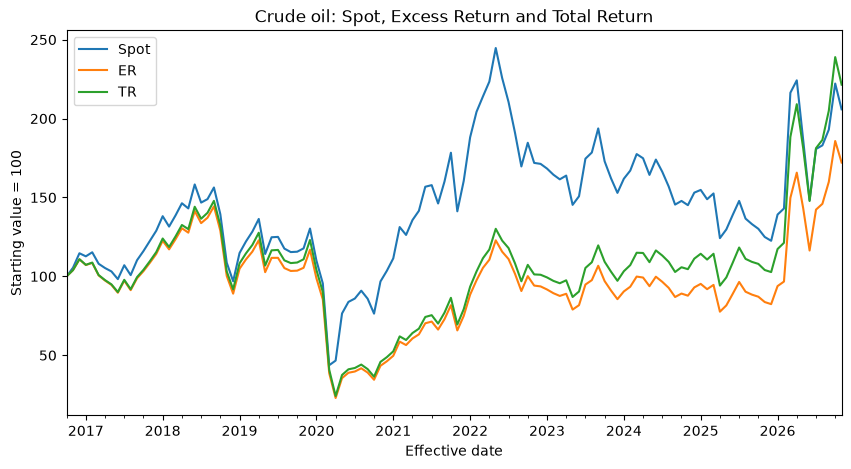

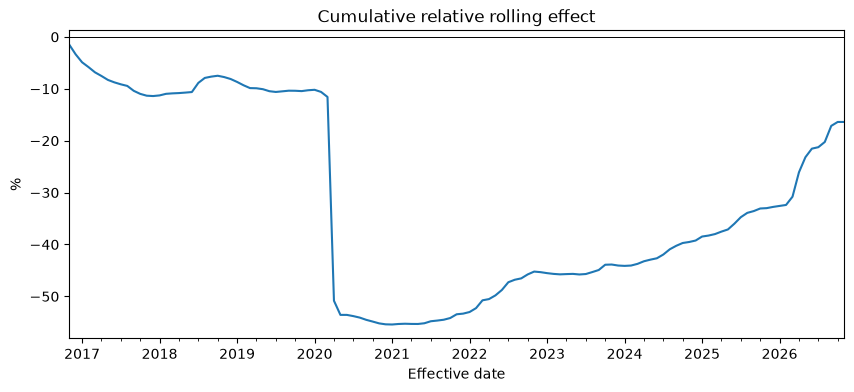


Regime comparison: 2016-11 to 2024-04
               Average roll (log pp/month)  Months
Regime                                            
Backwardation                        0.720      42
Contango                            -1.809      48


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load index data
indices = pd.read_csv("oil_indices.csv", sep=";")
indices.columns = indices.columns.str.strip()

# Remove disclaimer rows and convert Excel date numbers
dates = pd.to_numeric(indices["Effective date"], errors="coerce")
indices = indices.loc[dates.notna()].copy()

indices["Effective date"] = pd.to_datetime(
    dates.loc[dates.notna()],
    unit="D",
    origin="1899-12-30"
)

indices = indices.set_index("Effective date")[["Spot", "ER", "TR"]]

# Convert prices stored as text into numbers
for col in indices.columns:
    indices[col] = pd.to_numeric(
        indices[col].astype(str).str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

indices = indices.sort_index().dropna().resample("ME").last()

if len(indices) < 2 or indices.isna().any().any():
    raise ValueError("Check the index data: too few observations or missing months.")

if (indices <= 0).any().any():
    raise ValueError("Index levels must be positive to calculate log returns.")

# Load futures data
futures = pd.read_csv("oil_futures.csv", sep=";")
futures.columns = futures.columns.str.strip()

futures["Date"] = pd.to_datetime(
    futures["Date"].astype(str).str.strip(),
    format="mixed",
    errors="raise"
)

futures = futures.set_index("Date")[["F1", "F2"]]

for col in futures.columns:
    futures[col] = pd.to_numeric(
        futures[col].astype(str).str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

futures = futures.sort_index().dropna().resample("ME").last()

# Calculate monthly log returns
r = np.log(indices / indices.shift(1)).dropna()

# Total = Spot + Roll + Collateral
r["Roll"] = r["ER"] - r["Spot"]
r["Collateral"] = r["TR"] - r["ER"]

# Quantify the cumulative rolling effect
roll_effect = np.exp(r["Roll"].sum()) - 1

actual_wealth = 100 * np.exp(r["TR"].sum())
no_roll_wealth = 100 * np.exp(
    (r["Spot"] + r["Collateral"]).sum()
)

print(f"Return sample: {r.index.min():%Y-%m} to {r.index.max():%Y-%m}")
print(f"Cumulative relative rolling effect: {roll_effect:.2%}")
print(f"Actual ending wealth per $100: ${actual_wealth:.2f}")
print(f"Zero-roll counterfactual: ${no_roll_wealth:.2f}")
print(
    f"Wealth reduction from rolling: "
    f"${no_roll_wealth - actual_wealth:.2f}"
)

# Plot index performance starting at 100
wealth = 100 * indices / indices.iloc[0]

wealth.plot(figsize=(10, 5))
plt.title("Crude oil: Spot, Excess Return and Total Return")
plt.ylabel("Starting value = 100")
plt.show()

# Plot cumulative relative rolling effect
cumulative_roll = 100 * (np.exp(r["Roll"].cumsum()) - 1)

cumulative_roll.plot(figsize=(10, 4))
plt.axhline(0, color="black", linewidth=0.7)
plt.title("Cumulative relative rolling effect")
plt.ylabel("%")
plt.show()

# Classify months using the previous month-end's curve
r["Spread"] = (futures["F2"] - futures["F1"]).shift(1)
comparison = r.dropna(subset=["Spread"]).copy()

comparison["Regime"] = "Flat"
comparison.loc[comparison["Spread"] > 0, "Regime"] = "Contango"
comparison.loc[comparison["Spread"] < 0, "Regime"] = "Backwardation"

# Compare monthly roll components by regime
if comparison.empty:
    print("\nNo overlapping dates between index returns and futures data.")
else:
    summary = comparison.groupby("Regime")["Roll"].agg(["mean", "count"])
    summary["mean"] *= 100
    summary.columns = ["Average roll (log pp/month)", "Months"]

    print(
        f"\nRegime comparison: "
        f"{comparison.index.min():%Y-%m} to "
        f"{comparison.index.max():%Y-%m}"
    )
    print(summary.round(3))

### (B) Strech Part - code

In [4]:
import yfinance as yf
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Adjusted gold ETF prices
gold = yf.download("GLD", start="2010-01-01", end="2026-01-01", auto_adjust=True)["Close"].squeeze()

# 10-year real yield from FRED
tips = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFII10",index_col=0, parse_dates=True, na_values=".")["DFII10"]

# Align monthly observations
data = pd.concat(
    [gold.rename("Gold"), tips.rename("RealYield")], axis=1
).loc["2010":"2025"].resample("ME").last()

data["GoldReturn"] = 100 * np.log(data["Gold"]).diff()
data["YieldChange"] = data["RealYield"].diff()
data = data.dropna()

# Gold return = alpha + beta * change in real yield
model = sm.OLS(
    data["GoldReturn"], sm.add_constant(data["YieldChange"])
).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

print(model.summary())

[*********************100%***********************]  1 of 1 completed

                            OLS Regression Results                            
Dep. Variable:             GoldReturn   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     28.19
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           3.07e-07
Time:                        15:40:59   Log-Likelihood:                -538.12
No. Observations:                 191   AIC:                             1080.
Df Residuals:                     189   BIC:                             1087.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.7223      0.268      2.691      


/var/folders/bg/bbm4y5h10tb3qjxl22bkls4w0000gn/T/ipykernel_75271/1985168703.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  data = pd.concat(
